# 04.1 · transfer eval results — load & analyze the α-boost / multi-pivot runs

Parses `scripts/diff/q_transfer_eval.py` runs for **both** setups — **q-transfer** (`__a2_np1`) and **filter-transfer** (`__a2_np5`) — under `results/diff/{q,filter}_transfer/<model>/`. Each config folder has `results.json` (per-instance RAW artifacts + eval verdicts) and `meta.json` (config + summary rates). This notebook flattens every instance into one table and breaks the three evals — **causal** (oracle), **readout shift** (oracle), **gaze** (rule-based) — down across the setup / datatype / naming / language axes.

In [1]:
import sys, json
from pathlib import Path
sys.path.append("../..")
import numpy as np, pandas as pd
from IPython.display import display
from src.utils import env_utils

MODEL_SHORT = "Qwen2.5-Coder-32B-Instruct"        # <- the run to analyze
# results now live under a per-run tag folder: .../{setup}/{model}/{run_tag}/{config}/ .
# pick the run tag per setup (ph-{patch_heads}__a{alpha}; the α-boost run = ph-goal__a2).
SELECT = {"q_transfer": "ph-goal__a2", "filter_transfer": "ph-goal__a2"}
DIFF_DIR = Path(env_utils.DEFAULT_RESULTS_DIR) / "diff"

config_dirs = []
for setup_dir, run_tag in SELECT.items():
    root = DIFF_DIR / setup_dir / MODEL_SHORT / run_tag
    if not root.exists():
        print(f"!! no run dir {root}"); continue
    dirs = sorted(d for d in root.iterdir()
                  if d.is_dir() and (d / "results.json").exists())
    config_dirs += dirs
    print(f"{setup_dir} ({run_tag}): {len(dirs)} configs")
assert config_dirs, "no matching config folders — run q_transfer_eval.py first"
print(f"\n{len(config_dirs)} config folders total:")
for d in config_dirs: print("   ", d.parent.parent.parent.name, "/", d.parent.name, "/", d.name)

q_transfer (ph-goal__a2): 8 configs
filter_transfer (ph-goal__a2): 6 configs

14 config folders total:
    q_transfer / ph-goal__a2 / q__int__randnm__python-cpp
    q_transfer / ph-goal__a2 / q__int__randnm__python-python
    q_transfer / ph-goal__a2 / q__list_int__randnm__python-cpp
    q_transfer / ph-goal__a2 / q__list_int__randnm__python-python
    q_transfer / ph-goal__a2 / q__list_str__randnm__python-cpp
    q_transfer / ph-goal__a2 / q__list_str__randnm__python-python
    q_transfer / ph-goal__a2 / q__str__randnm__python-cpp
    q_transfer / ph-goal__a2 / q__str__randnm__python-python
    filter_transfer / ph-goal__a2 / filter__list_int__targeted__python-cpp
    filter_transfer / ph-goal__a2 / filter__list_int__targeted__python-python
    filter_transfer / ph-goal__a2 / filter__list_str__targeted__python-cpp
    filter_transfer / ph-goal__a2 / filter__list_str__targeted__python-python
    filter_transfer / ph-goal__a2 / filter__str__targeted__python-cpp
    filter_transfer / ph-

## Flatten all instances into one table

In [2]:
def _g(d, *ks):
    for k in ks: d = (d or {}).get(k) if isinstance(d, dict) else None
    return d
rows = []
for d in config_dirs:
    for r in json.loads((d / "results.json").read_text()):
        rows.append(dict(
            config=d.name, setup=r.get("setup", ""), datatype=r["datatype"], naming=r["naming"],
            lang=f'{r["src_lang"]}->{r["dst_lang"]}',
            expected_next=r["expected_next"], dst_next=r["dst_next"],
            causal_triggered=_g(r, "causal", "triggered"), causal_label=_g(r, "causal", "label"),
            readout_valid=_g(r, "readout", "valid"), readout_shifted=_g(r, "readout", "shifted"),
            ro_source=_g(r, "readout", "source"), ro_dest=_g(r, "readout", "dest"),
            ro_patched=_g(r, "readout", "patched"),
            gaze_shifted=_g(r, "gaze", "shifted"), gaze_margin=_g(r, "gaze", "margin"),
            expected_next_desc=r["expected_next_desc"], dst_next_desc=r["dst_next_desc"],
            gen_patched=r["raw"].get("gen_patched", ""),
            ro_src_txt=r["raw"].get("ro_src", ""), ro_dst_txt=r["raw"].get("ro_dst", ""),
            ro_pat_txt=r["raw"].get("ro_patched", ""),
        ))
df = pd.DataFrame(rows)
# numeric copies of the boolean verdicts (True->1, False->0, missing->NaN) for group means
METRICS = ["causal_triggered", "readout_valid", "readout_shifted", "gaze_shifted"]
for c in METRICS:
    df[c + "_f"] = df[c].map({True: 1.0, False: 0.0})
MF = [c + "_f" for c in METRICS]
print(f"{len(df)} instances · setups={sorted(df.setup.unique())} · {df.config.nunique()} configs")
print(df.groupby("setup").size().to_string())
df.head()

1744 instances · setups=['filter', 'q'] · 14 configs
setup
filter     720
q         1024


,config,setup,datatype,naming,lang,expected_next,dst_next,causal_triggered,causal_label,readout_valid,...,expected_next_desc,dst_next_desc,gen_patched,ro_src_txt,ro_dst_txt,ro_pat_txt,causal_triggered_f,readout_valid_f,readout_shifted_f,gaze_shifted_f
0,q__int__randnm__python-cpp,q,int,natural,python->cpp,is_prime,is_positive,True,src,True,...,whether the number is prime,whether the number is positive,bool is_positive = (n > 1) && (n != 2 || (n %...,"Sure, but I need to see the specific line of c...",I'm checking if the variable is greater than z...,I'm checking if the current number is prime.,1.0,1.0,1.0,1.0
1,q__int__randnm__python-cpp,q,int,natural,python->cpp,count_set_bits,sign,True,src,True,...,the number of set bits in the binary represent...,the sign of the number,int sign = __builtin_popcount(n);\n int s...,I'm counting the number of 1s in the binary re...,"I'm checking if the number is positive, negati...",I'm counting the number of 1s in the binary re...,1.0,1.0,1.0,1.0
2,q__int__randnm__python-cpp,q,int,natural,python->cpp,is_two_digit,is_palindrome,True,src,True,...,whether the number has exactly two digits,whether the number reads the same forwards and...,bool is_two_digit = (n >= 10 && n <= 99);\n ...,I'm checking if the variable has exactly two d...,I'm checking if the current line of code is a ...,I'm checking if the variable is a two-digit nu...,1.0,1.0,1.0,1.0
3,q__int__randnm__python-cpp,q,int,letters,python->cpp,last_digit,is_even,False,dst,True,...,the last decimal digit,whether the number is even,bool b = (n % 2 == 0);\n int c = abs(n);\...,I'm examining the last character of the code l...,I'm checking if the variable is even (using `v...,I'm looking at the last character of the varia...,0.0,1.0,1.0,1.0
4,q__int__randnm__python-cpp,q,int,letters,python->cpp,sign,absolute_value,True,src,True,...,the sign of the number,the absolute value,int b = (n > 0) - (n < 0);\n int c = (n > ...,I'm checking the sign of the variable.,I'm calculating the absolute value of the vari...,I'm checking the sign of the variable to deter...,1.0,1.0,1.0,1.0


## Overall rates

In [3]:
def _rate(s):
    s = s.dropna()
    return f"{s.mean():.1%}  (n={len(s)})" if len(s) else "— (n=0)"
valid = df[df.readout_valid == True]
print("OVERALL")
print("  causal triggered      :", _rate(df.causal_triggered_f))
print("  readout valid         :", _rate(df.readout_valid_f))
print("  readout shifted (all) :", _rate(df.readout_shifted_f))
print("  readout shifted|valid :", _rate(valid.readout_shifted_f), " <- the meaningful one")
print("  gaze shifted          :", _rate(df.gaze_shifted_f))
print("\nBY SETUP (causal | readout-shift|valid):")
for s, sub in df.groupby("setup"):
    sv = sub[sub.readout_valid == True]
    print(f"  {s:8s}: causal {_rate(sub.causal_triggered_f)} | shift|valid {_rate(sv.readout_shifted_f)}")

OVERALL
  causal triggered      : 84.5%  (n=1744)
  readout valid         : 80.6%  (n=1744)
  readout shifted (all) : 89.0%  (n=1744)
  readout shifted|valid : 95.0%  (n=1406)  <- the meaningful one
  gaze shifted          : 98.6%  (n=1744)

BY SETUP (causal | readout-shift|valid):
  filter  : causal 71.5%  (n=720) | shift|valid 96.0%  (n=554)
  q       : causal 93.6%  (n=1024) | shift|valid 94.2%  (n=852)


## Breakdown by each axis

In [4]:
# success rate across each axis, broken down by the three metrics.
# readout-shift is reported among VALID cases only (source->SRC & dest->DST) — the meaningful denominator.
_FMT = ["causal", "readout_valid", "readout_shift|valid", "gaze"]

def axis_summary(df, axis):
    g = df.groupby(axis)
    vsh = df[df.readout_valid == True].groupby(axis).readout_shifted_f.mean()
    out = pd.DataFrame({
        "n": g.size(),
        "causal": g.causal_triggered_f.mean(),
        "readout_valid": g.readout_valid_f.mean(),
        "readout_shift|valid": vsh,
        "gaze": g.gaze_shifted_f.mean(),
    })
    # prepend an ALL row
    allrow = pd.DataFrame({
        "n": [len(df)], "causal": [df.causal_triggered_f.mean()],
        "readout_valid": [df.readout_valid_f.mean()],
        "readout_shift|valid": [df[df.readout_valid == True].readout_shifted_f.mean()],
        "gaze": [df.gaze_shifted_f.mean()]}, index=["ALL"])
    return pd.concat([allrow, out])

for axis in ["setup", "datatype", "naming", "lang"]:
    print(f"=== by {axis} ===")
    display(axis_summary(df, axis).style.format({"n": "{:.0f}", **{c: "{:.1%}" for c in _FMT}}, na_rep="—"))

=== by setup ===


,n,causal,readout_valid,readout_shift|valid,gaze
ALL,1744,84.5%,80.6%,95.0%,98.6%
filter,720,71.5%,76.9%,96.0%,96.8%
q,1024,93.6%,83.2%,94.2%,99.9%


=== by datatype ===


,n,causal,readout_valid,readout_shift|valid,gaze
ALL,1744,84.5%,80.6%,95.0%,98.6%
int,256,94.1%,82.8%,90.6%,99.6%
list[int],512,71.3%,78.1%,93.0%,96.3%
list[str],512,87.9%,83.2%,97.7%,99.8%
str,464,89.9%,79.3%,96.5%,99.4%


=== by naming ===


,n,causal,readout_valid,readout_shift|valid,gaze
ALL,1744,84.5%,80.6%,95.0%,98.6%
letters,487,93.4%,79.7%,91.8%,100.0%
natural,537,93.7%,86.4%,96.3%,99.8%
targeted,720,71.5%,76.9%,96.0%,96.8%


=== by lang ===


,n,causal,readout_valid,readout_shift|valid,gaze
ALL,1744,84.5%,80.6%,95.0%,98.6%
python->cpp,872,82.8%,77.3%,93.5%,99.0%
python->python,872,86.1%,83.9%,96.3%,98.3%


### Headline metric as a datatype × language cross-tab

Causal success split by both axes at once — reads off whether cross-language (py→cpp) transfer costs anything relative to py→py, per datatype.

In [5]:
# headline metric (causal success) as a datatype x lang cross-tab — where does cross-language transfer cost us?
piv = df.pivot_table(index=["setup", "datatype"], columns="lang", values="causal_triggered_f", aggfunc="mean")
piv["all"] = df.groupby(["setup", "datatype"]).causal_triggered_f.mean()
display(piv.style.format("{:.1%}", na_rep="—").set_caption("causal success · setup×datatype x lang"))

## Readout shift among VALID cases, by axis

The clean readouts must land as expected (source→SRC, dest→DST) for the case to be analyzable; restrict to those, then ask how often the patched readout moved to the SRC target.

In [6]:
v = df[df.readout_valid == True]
if len(v):
    for axis in ["setup", "datatype", "naming", "lang"]:
        g = v.groupby(axis)["readout_shifted_f"].agg(["mean", "size"]).rename(
            columns={"mean": "shift|valid", "size": "n_valid"})
        print(f"=== {axis} ==="); display(g.style.format({"shift|valid": "{:.1%}"}))
    print("patched-readout label distribution (valid cases):")
    display(v.ro_patched.value_counts(dropna=False))
else:
    print("no valid readout cases (oracle may have been skipped with --no-oracle)")

=== setup ===


,shift|valid,n_valid
setup,,
filter,96.0%,554
q,94.2%,852


=== datatype ===


,shift|valid,n_valid
datatype,,
int,90.6%,212
list[int],93.0%,400
list[str],97.7%,426
str,96.5%,368


=== naming ===


,shift|valid,n_valid
naming,,
letters,91.8%,388
natural,96.3%,464
targeted,96.0%,554


=== lang ===


,shift|valid,n_valid
lang,,
python->cpp,93.5%,674
python->python,96.3%,732


patched-readout label distribution (valid cases):


ro_patched
src        1256
both         79
neither      63
dst           8
Name: count, dtype: int64

## Agreement between the three signals

Do causal success, readout shift, and gaze shift co-occur on the same instances?

In [7]:
sig = df.dropna(subset=["causal_triggered", "readout_shifted", "gaze_shifted"])
if len(sig):
    print(f"n={len(sig)} instances with all three signals")
    print("causal vs readout_shifted:")
    display(pd.crosstab(sig.causal_triggered, sig.readout_shifted))
    print("causal vs gaze_shifted:")
    display(pd.crosstab(sig.causal_triggered, sig.gaze_shifted))
else:
    print("need oracle + gaze verdicts on the same instances")

n=1744 instances with all three signals
causal vs readout_shifted:


readout_shifted,False,True
causal_triggered,,
False,56,215
True,136,1337


causal vs gaze_shifted:


gaze_shifted,False,True
causal_triggered,,
False,20,251
True,4,1469


## Gaze margin distribution

`margin = mean Δattn on SRC-target span − mean Δattn on DST-target span` (patched − clean). >0 ⇒ gaze moved toward the SRC goal.

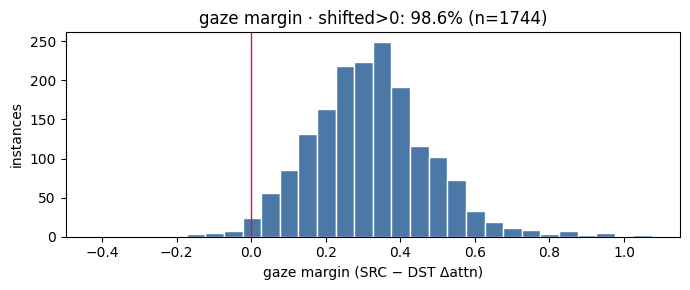

In [8]:
import matplotlib.pyplot as plt
m = df.gaze_margin.dropna().astype(float)
if len(m):
    fig, ax = plt.subplots(figsize=(7, 3))
    ax.hist(m, bins=30, color="#4c78a8", edgecolor="white")
    ax.axvline(0, color="crimson", lw=1)
    ax.set_xlabel("gaze margin (SRC − DST Δattn)"); ax.set_ylabel("instances")
    ax.set_title(f"gaze margin · shifted>{0}: {(m > 0).mean():.1%} (n={len(m)})")
    plt.tight_layout(); plt.show()
else:
    print("no gaze margins")

## Gaze — corrected metric: does the patch make gaze prefer SRC over DST?

The saved `gaze.shifted` used the patched−clean **delta > 0** with no reference point, so it fired ~100% and wasn't discriminative. What we actually want: **after the patch**, does the pivot gaze more at the SRC left-out target span than at the DST left-out span — `gaze(SRC.leftout) > gaze(DST.leftout)` on the **absolute** patched attention. The credibility check is the **clean baseline**: before the patch, gaze should prefer the DST frontier (SRC>DST rare). Spans are located by string-matching each target description inside the saved `task_tokens` (no model needed).

In [9]:
# recompute gaze from the saved absolute attention (attn_patched / attn_clean over task_positions).
# spans: match each target description within the joined task_tokens -> token-index subset.
def _span_idx(task_tokens, desc):
    joined = "".join(task_tokens)
    ci = joined.find(desc)
    if ci < 0:                                   # tolerate whitespace/case drift
        ci = joined.lower().find(desc.lower().strip())
    if ci < 0:
        return []
    cj, idx, pos = ci + len(desc), [], 0
    for i, t in enumerate(task_tokens):
        if pos + len(t) > ci and pos < cj:
            idx.append(i)
        pos += len(t)
    return idx

recs, miss = [], 0
for d in config_dirs:
    for r in json.loads((d / "results.json").read_text()):
        raw = r["raw"]
        si, di = _span_idx(raw["task_tokens"], r["expected_next_desc"]), _span_idx(raw["task_tokens"], r["dst_next_desc"])
        if not si or not di:
            miss += 1
            recs.append((r["expected_next"], np.nan, np.nan, np.nan, np.nan)); continue
        ap, ac = np.asarray(raw["attn_patched"], float), np.asarray(raw["attn_clean"], float)
        recs.append((r["expected_next"], ap[si].mean(), ap[di].mean(), ac[si].mean(), ac[di].mean()))
gz = pd.DataFrame(recs, columns=["_chk", "src_pat", "dst_pat", "src_clean", "dst_clean"])
assert (gz["_chk"].values == df["expected_next"].values).all(), "row alignment mismatch"
for c in ["src_pat", "dst_pat", "src_clean", "dst_clean"]:
    df["gaze_" + c] = gz[c].values
df["gaze_abs"]     = df.gaze_src_pat > df.gaze_dst_pat          # patched: gaze(SRC) > gaze(DST)?
df["gaze_clean"]   = df.gaze_src_clean > df.gaze_dst_clean      # baseline: before the patch
df["gaze_abs_f"]   = df.gaze_abs.map({True: 1.0, False: 0.0})
df["gaze_abs_margin"] = df.gaze_src_pat - df.gaze_dst_pat

print(f"span-miss={miss}/{len(df)}")
print(f"clean baseline  gaze(SRC)>gaze(DST) : {df.gaze_clean.mean():.1%}   <- should be LOW (clean prefers DST frontier)")
print(f"PATCHED         gaze(SRC)>gaze(DST) : {df.gaze_abs.mean():.1%}   <- the patch flips gaze toward SRC")
print(f"(old delta>0 metric was            : {df.gaze_shifted_f.mean():.1%})")

for axis in ["setup", "datatype", "naming", "lang"]:
    g = df.groupby(axis).agg(n=("gaze_abs", "size"), clean=("gaze_clean", "mean"), patched=("gaze_abs", "mean"))
    print(f"=== by {axis} ===")
    display(g.style.format({"clean": "{:.1%}", "patched": "{:.1%}"}))

# gaze-shift is near-necessary but not sufficient: does it co-occur with causal success?
print("corrected gaze (patched SRC>DST) vs causal success:")
display(pd.crosstab(df.causal_triggered, df.gaze_abs, dropna=False))

span-miss=0/1744
clean baseline  gaze(SRC)>gaze(DST) : 1.8%   <- should be LOW (clean prefers DST frontier)
PATCHED         gaze(SRC)>gaze(DST) : 98.6%   <- the patch flips gaze toward SRC
(old delta>0 metric was            : 98.6%)
=== by setup ===


,n,clean,patched
setup,,,
filter,720,2.8%,96.8%
q,1024,1.2%,99.9%


=== by datatype ===


,n,clean,patched
datatype,,,
int,256,1.2%,99.6%
list[int],512,3.3%,96.3%
list[str],512,0.6%,99.8%
str,464,1.9%,99.4%


=== by naming ===


,n,clean,patched
naming,,,
letters,487,1.0%,100.0%
natural,537,1.3%,99.8%
targeted,720,2.8%,96.8%


=== by lang ===


,n,clean,patched
lang,,,
python->cpp,872,2.3%,99.0%
python->python,872,1.4%,98.3%


corrected gaze (patched SRC>DST) vs causal success:


gaze_abs,False,True
causal_triggered,,
False,20,251
True,4,1469


## Qualitative — inspect a few instances

Eyeball the patched generation + the three readouts against the SRC/DST targets.

In [10]:
def show_instance(row):
    print(f"[{row.config}]  expected(SRC)={row.expected_next!r} ({row.expected_next_desc})")
    print(f"                 dst_next   ={row.dst_next!r} ({row.dst_next_desc})")
    print(f"  causal={row.causal_label} triggered={row.causal_triggered} | "
          f"readout {row.ro_source}->{row.ro_dest}->{row.ro_patched} "
          f"(valid={row.readout_valid}, shifted={row.readout_shifted}) | gaze_shift={row.gaze_shifted}")
    print("  readout src :", row.ro_src_txt)
    print("  readout dst :", row.ro_dst_txt)
    print("  readout pat :", row.ro_pat_txt)
    print("  patched gen :\n    " + row.gen_patched.replace("\n", "\n    "))
    print("-" * 90)

# a few triggered and a few not (fall back to head() if oracle skipped)
trig = df[df.causal_triggered == True].head(2)
notrig = df[df.causal_triggered == False].head(2)
sample = pd.concat([trig, notrig]) if len(trig) + len(notrig) else df.head(3)
for _, row in sample.iterrows():
    show_instance(row)

[q__int__randnm__python-cpp]  expected(SRC)='is_prime' (whether the number is prime)
                 dst_next   ='is_positive' (whether the number is positive)
  causal=src triggered=True | readout src->dst->src (valid=True, shifted=True) | gaze_shift=True
  readout src : Sure, but I need to see the specific line of code to determine if it's doing something at all and what that might be. Here's a quick check for you:

```python
def is_prime(n):
    if n <= 1:
        return False
    if n <= 3:
        return n in [2, 3]
    if n % 2 == 0:
        return False
    for i in range(2, int(n**0.5) + 1):
        if n % i == 0:
            return False
    return True

def check_line_of_code(line):

  readout dst : I'm checking if the variable is greater than zero to determine if it's positive.
  readout pat : I'm checking if the current number is prime.
  patched gen :
     bool is_positive = (n > 1) && (n != 2 || (n % 2 != 0 && n != 1));
         int last_decimal_digit = abs(n) % 10;
    

## Config-level summary (from each `meta.json`)

In [11]:
metas = [json.loads((d / "meta.json").read_text()) for d in config_dirs if (d / "meta.json").exists()]
mdf = pd.DataFrame(metas)
cols = ["setup", "datatype", "naming", "src_lang", "dst_lang", "alpha", "n_pivot", "n_instances",
        "causal_trigger_rate", "readout_valid_rate", "readout_shift_rate_valid",
        "gaze_shift_rate", "gaze_clean_baseline_rate"]
display(mdf[[c for c in cols if c in mdf.columns]])

,setup,datatype,naming,src_lang,dst_lang,alpha,n_pivot,n_instances,causal_trigger_rate,readout_valid_rate,readout_shift_rate_valid,gaze_shift_rate,gaze_clean_baseline_rate
0,q,int,random,python,cpp,2.0,1,128,0.929688,0.828125,0.886792,0.992188,0.007812
1,q,int,random,python,python,2.0,1,128,0.953125,0.828125,0.924528,1.000000,0.015625
2,q,list[int],random,python,cpp,2.0,1,128,0.937500,0.828125,0.905660,1.000000,0.007812
3,q,list[int],random,python,python,2.0,1,128,0.953125,0.851562,0.944954,1.000000,0.023438
4,q,list[str],random,python,cpp,2.0,1,128,0.914062,0.750000,0.958333,1.000000,0.007812
5,q,list[str],random,python,python,2.0,1,128,0.953125,0.859375,0.981818,1.000000,0.015625
6,q,str,random,python,cpp,2.0,1,128,0.890625,0.765625,0.959184,1.000000,0.007812
7,q,str,random,python,python,2.0,1,128,0.953125,0.945312,0.975207,1.000000,0.007812
8,filter,list[int],targeted,python,cpp,2.0,5,128,0.460938,0.687500,0.920455,0.953125,0.078125
9,filter,list[int],targeted,python,python,2.0,5,128,0.500000,0.757812,0.948454,0.898438,0.023438
